In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
import warnings

warnings.filterwarnings("ignore")

df = pd.read_csv("creditcard.csv")
print("Data loaded successfully!")
print(df["Class"].value_counts())

Data loaded successfully!
Class
0    284315
1       492
Name: count, dtype: int64


In [4]:
# Scale the Amount and Time columns
scaler = StandardScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])
df["Time_scaled"] = scaler.fit_transform(df[["Time"]])

# Drop the original Amount and Time columns
X = df.drop(["Class", "Time", "Amount"], axis=1)
y = df["Class"]

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Original training set shape:", y_train.value_counts())

Original training set shape: Class
0    227451
1       394
Name: count, dtype: int64


In [5]:
# Apply SMOTE to the training data only
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Original training set shape:", y_train.value_counts())
print("Resampled training set shape:", y_train_res.value_counts())

Original training set shape: Class
0    227451
1       394
Name: count, dtype: int64
Resampled training set shape: Class
0    227451
1    227451
Name: count, dtype: int64


In [6]:
# Train Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_res, y_train_res)

# Make predictions
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

# Evaluate
print("=== Logistic Regression Results ===")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"PR-AUC Score: {average_precision_score(y_test, y_prob_lr):.4f}")

=== Logistic Regression Results ===
Confusion Matrix:
[[55406  1458]
 [    8    90]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

ROC-AUC Score: 0.9698
PR-AUC Score: 0.7249


In [7]:
# Train Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_res, y_train_res)

# Make predictions
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

# Evaluate
print("=== Logistic Regression Results ===")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"PR-AUC Score: {average_precision_score(y_test, y_prob_lr):.4f}")

=== Logistic Regression Results ===
Confusion Matrix:
[[55406  1458]
 [    8    90]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

ROC-AUC Score: 0.9698
PR-AUC Score: 0.7249


In [8]:
# Train Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_res, y_train_res)

# Make predictions
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Evaluate
print("=== Random Forest Results ===")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC Score: {average_precision_score(y_test, y_prob_rf):.4f}")

=== Random Forest Results ===
Confusion Matrix:
[[56846    18]
 [   20    78]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.81      0.80      0.80        98

    accuracy                           1.00     56962
   macro avg       0.91      0.90      0.90     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9716
PR-AUC Score: 0.8699


=== Risk Level Distribution ===
Risk_Level
Low Risk       56857
High Risk         74
Medium Risk       31
Name: count, dtype: int64

=== Top 10 Important Features ===
V14    0.200264
V10    0.121395
V4     0.116018
V17    0.092851
V12    0.078912
V11    0.072763
V3     0.058163
V7     0.030421
V16    0.028119
V2     0.021535
dtype: float64


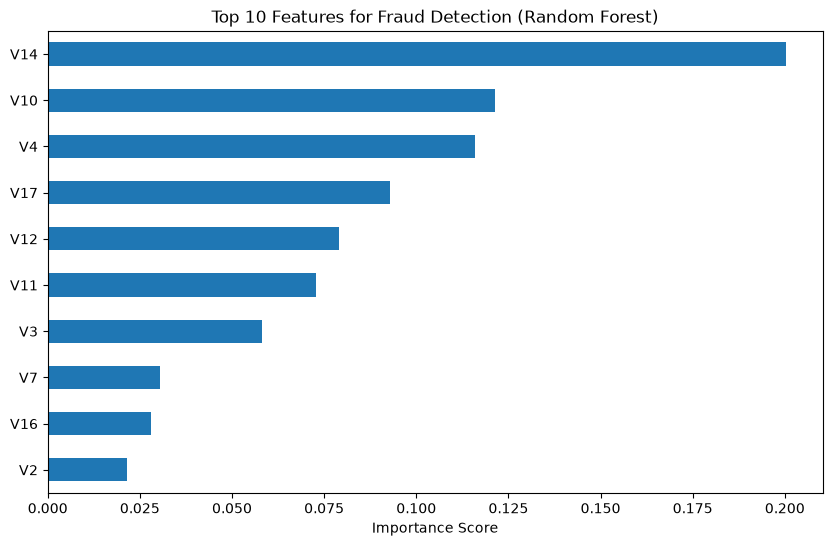

In [11]:
# 1. Risk Level Interpretation
def get_risk_level(prob):
    if prob >= 0.8:
        return "High Risk"
    elif prob >= 0.4:
        return "Medium Risk"
    else:
        return "Low Risk"

# Create a DataFrame with predictions and probabilities
risk_df = pd.DataFrame({
    "Fraud_Probability": y_prob_rf,
    "Actual_Class": y_test.values
})
risk_df["Risk_Level"] = risk_df["Fraud_Probability"].apply(get_risk_level)

print("=== Risk Level Distribution ===")
print(risk_df["Risk_Level"].value_counts())

# 2. Feature Importance
importances = pd.Series(rf.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(10)

print("\n=== Top 10 Important Features ===")
print(top_features)

# 3. Visualize Feature Importance
plt.figure(figsize=(10, 6))
top_features.plot(kind="barh")
plt.title("Top 10 Features for Fraud Detection (Random Forest)")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.savefig("plots/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()